<a href="https://colab.research.google.com/github/anmoltyagi12/online_retail_dashboard/blob/main/retail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
uploaded = files.upload()

Saving Online_Retail.xlsx to Online_Retail.xlsx


In [5]:
import pandas as pd
import numpy as np
df = pd.read_excel("Online_Retail.xlsx")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.info()
print("\nColumn names:")
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:
missing_desc = df[
    df["StockCode"].notna() &
    df["Description"].isna()]
print("Rows with StockCode but missing Description:", len(missing_desc))
missing_desc[["StockCode", "Description"]].head(10)

Rows with StockCode but missing Description: 1454


,StockCode,Description
622,22139,NaN
1970,21134,NaN
1971,22145,NaN
1972,37509,NaN
1987,85226A,NaN
1988,85044,NaN
2024,20950,NaN
2025,37461,NaN
2026,84670,NaN
2406,21777,NaN


In [9]:

# Keep rows that have both a StockCode and a Description
valid_descriptions = df[
    df["StockCode"].notna() &
    df["Description"].notna()].copy()

# Remove whitespace and exclude empty descriptions
valid_descriptions["Description"] = (
    valid_descriptions["Description"].astype(str).str.strip())

valid_descriptions = valid_descriptions[
    valid_descriptions["Description"] != ""]

# Find the most common description for each StockCode
description_map = (
    valid_descriptions.groupby("StockCode")["Description"].agg(lambda s: s.mode().iloc[0]))
print("Stock codes with known descriptions:", len(description_map))

description_map.head(10)

Stock codes with known descriptions: 3958


,Description
StockCode,
10002,INFLATABLE POLITICAL GLOBE
10080,GROOVY CACTUS INFLATABLE
10120,DOGGY RUBBER
10125,MINI FUNKY DESIGN TAPES
10133,COLOURING PENCILS BROWN TUBE
10135,COLOURING PENCILS BROWN TUBE
11001,ASSTD DESIGN RACING CAR PEN
15030,FAN BLACK FRAME
15034,PAPER POCKET TRAVELING FAN


In [10]:
# Count missing descriptions before filling
before = df["Description"].isna().sum()

# Fill only missing descriptions using the StockCode mapping
mask = df["Description"].isna()

df.loc[mask, "Description"] = (
    df.loc[mask, "StockCode"].map(description_map)
)

# Count missing descriptions after filling
after = df["Description"].isna().sum()

print("Missing descriptions before:", before)
print("Descriptions successfully filled:", before - after)
print("Missing descriptions remaining:", after)

Missing descriptions before: 1454
Descriptions successfully filled: 1342
Missing descriptions remaining: 112


In [11]:
print("Missing CustomerIDs:", df["CustomerID"].isna().sum())
print("Total rows retained:", len(df))

Missing CustomerIDs: 135080
Total rows retained: 541909


In [12]:
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()
print("Rows after removing exact duplicates:", len(df))

Exact duplicate rows: 5268
Rows after removing exact duplicates: 536641


In [13]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()

df["IsCancellation"] = (df["InvoiceNo"].str.startswith("C", na=False))
print("Cancellation rows:", df["IsCancellation"].sum())

df[df["IsCancellation"]].head()

Cancellation rows: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,True
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,True
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True


In [14]:
print("Final dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum())

print("\nFirst five cleaned records:")
display(df.head())

Final dataset shape: (536641, 9)

Remaining missing values:
InvoiceNo              0
StockCode              0
Description          112
Quantity               0
InvoiceDate            0
UnitPrice              0
CustomerID        135037
Country                0
IsCancellation         0
dtype: int64

First five cleaned records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False


In [15]:
output_file = "Online_Retail_Cleaned.xlsx"
df.to_excel(output_file, index=False)
print("Cleaned dataset saved successfully!")

from google.colab import files
files.download(output_file)

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from google.colab import files
uploaded = files.upload()

Saving Online_Retail_Cleaned.xlsx to Online_Retail_Cleaned (1).xlsx


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Online_Retail_Cleaned.xlsx")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

#calculate revenue
df["LineTotal"] = df["Quantity"] * df["UnitPrice"]

#sales data for EDA, excluding cancellations and invalid sales values
sales_df = df[
    (~df["IsCancellation"].fillna(False).astype(bool))
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

print("Original dataset:", df.shape)
print("Sales dataset:", sales_df.shape)

display(sales_df.head())

Original dataset: (536641, 10)
Sales dataset: (524878, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineTotal
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34


,YearMonth,LineTotal
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


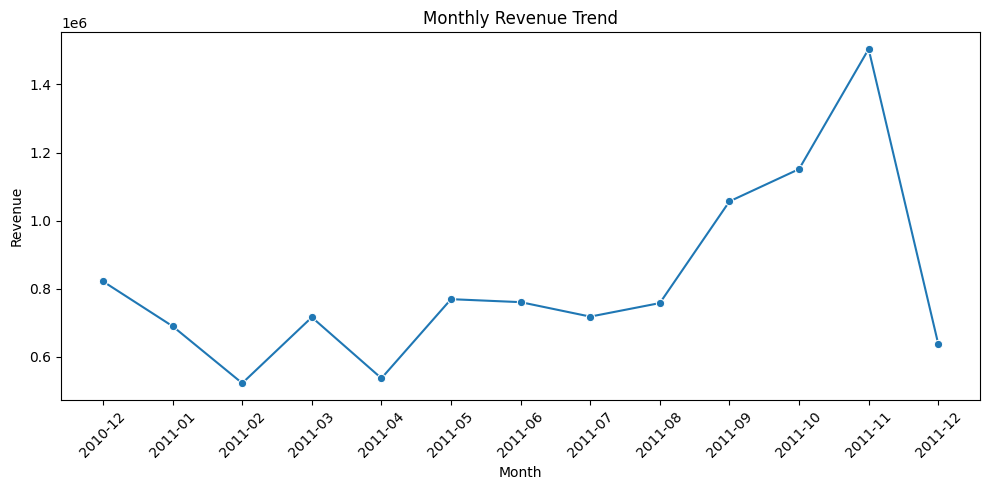

In [18]:
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_revenue = (
    sales_df.groupby("YearMonth")["LineTotal"]
    .sum()
    .reset_index()
)
monthly_revenue["YearMonth"] = monthly_revenue["YearMonth"].astype(str)
display(monthly_revenue)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_revenue,
    x="YearMonth",
    y="LineTotal",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Best-Selling Products:


,Description,Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48371
4,WHITE HANGING HEART T-LIGHT HOLDER,37872
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


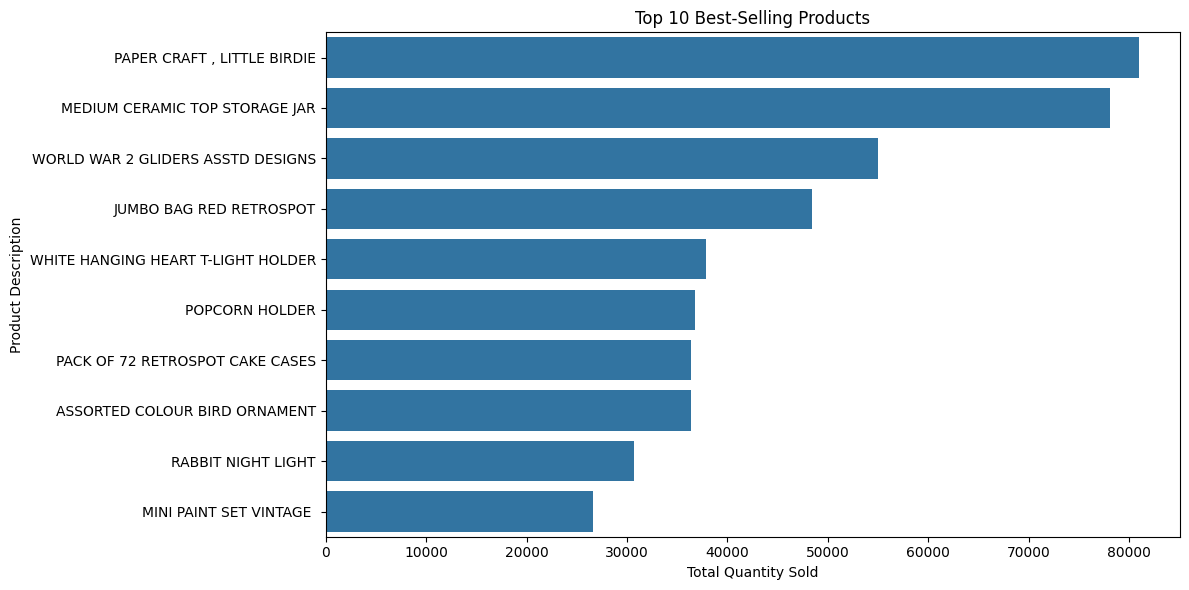

In [19]:
#top 10 products
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
print("Top 10 Best-Selling Products:")
display(top_products)

#results
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Quantity",
    y="Description"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

First 10 customers:


,CustomerID,PurchaseFrequency
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
5,12352.0,8
6,12353.0,1
7,12354.0,1
8,12355.0,1
9,12356.0,3



Total identified customers: 4338
Average purchase frequency: 4.27


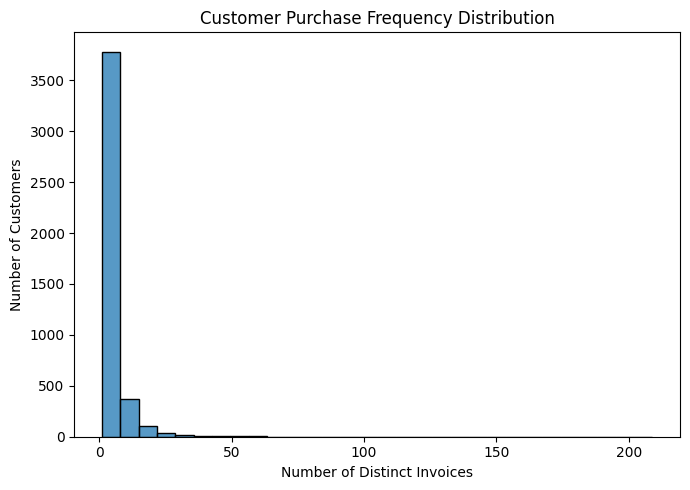

In [20]:
customer_frequency = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index(name="PurchaseFrequency")
)

print("First 10 customers:")
display(customer_frequency.head(10))
print("\nTotal identified customers:",
      customer_frequency["CustomerID"].nunique())
print("Average purchase frequency:",
      round(customer_frequency["PurchaseFrequency"].mean(), 2))

#plot purchase frequency distribution
plt.figure(figsize=(7, 5))
sns.histplot(
    data=customer_frequency,
    x="PurchaseFrequency",
    bins=30
)
plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Top 10 Countries by Revenue:


,Country,LineTotal
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


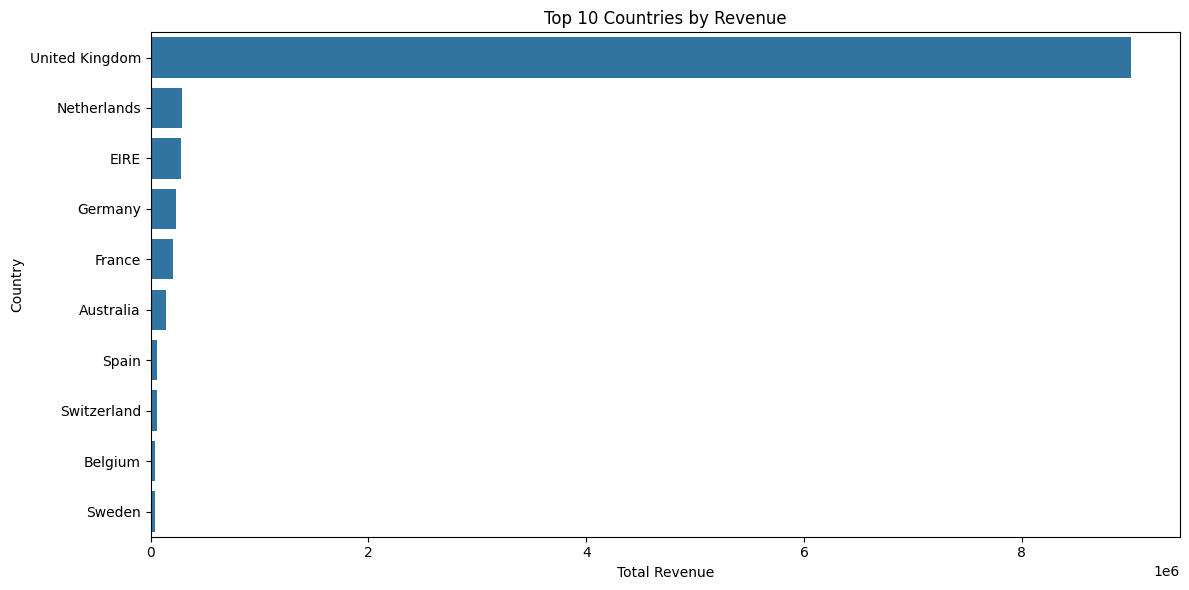

In [21]:
country_revenue = (
    sales_df.groupby("Country")["LineTotal"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index())

print("Top 10 Countries by Revenue:")
display(country_revenue)
plt.figure(figsize=(12, 6))
sns.barplot(
    data=country_revenue,
    x="LineTotal",
    y="Country")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [22]:
with pd.ExcelWriter("Module_2_EDA_Results.xlsx") as writer:
    monthly_revenue.to_excel(
        writer, sheet_name="Monthly Revenue", index=False
    )
    top_products.to_excel(writer, sheet_name="Top Products", index=False)
    customer_frequency.to_excel(writer, sheet_name="Purchase Frequency", index=False)
    country_revenue.to_excel(writer, sheet_name="Country Revenue", index=False)

from google.colab import files
files.download("Module_2_EDA_Results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Top 10 Best-Selling Products by Quantity Sold:


,Description,Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48371
4,WHITE HANGING HEART T-LIGHT HOLDER,37872
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


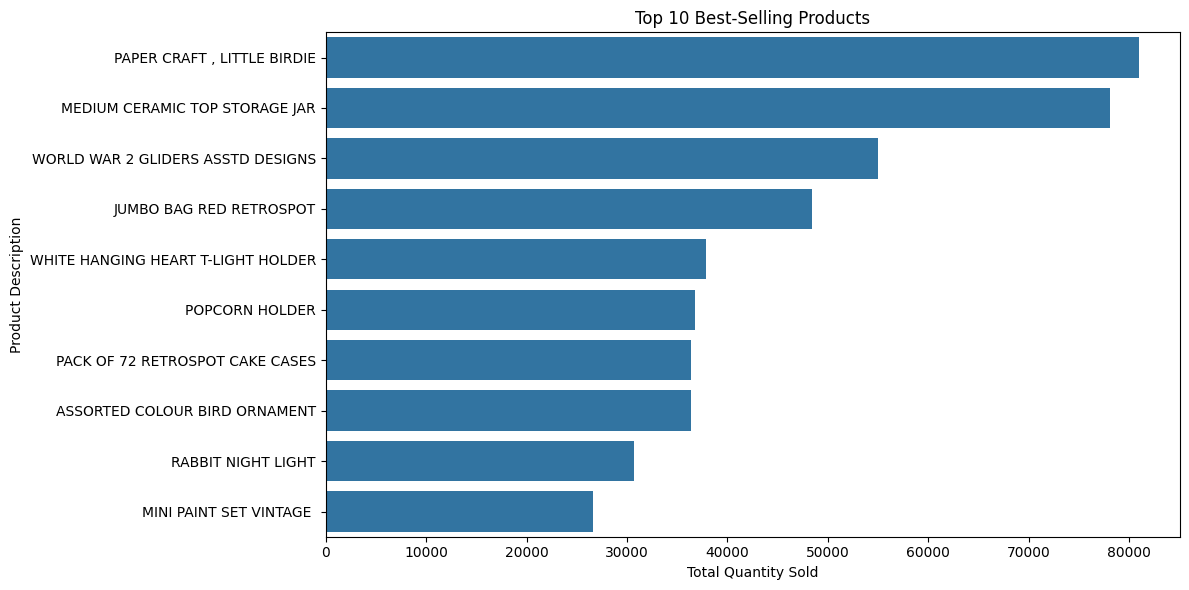

In [23]:
# Calculate total quantity sold for each product
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Display the results
print("Top 10 Best-Selling Products by Quantity Sold:")
display(top_products)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Quantity",
    y="Description"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rfm_data = sales_df.copy()

#transactions with a known CustomerID
rfm_data = rfm_data.dropna(subset=["CustomerID"]).copy()

rfm_data["InvoiceDate"] = pd.to_datetime(rfm_data["InvoiceDate"])
rfm_data["LineTotal"] = rfm_data["Quantity"] * rfm_data["UnitPrice"]

print("Transactions available for RFM:", len(rfm_data))
print("Unique customers:", rfm_data["CustomerID"].nunique())
display(rfm_data.head())

Transactions available for RFM: 392692
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineTotal,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12


In [25]:
reference_date = rfm_data["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = (
    rfm_data.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate",
                 lambda x: (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("LineTotal", "sum")
    )
    .reset_index()
)

print("RFM table:")
display(rfm.head(10))

print("\nRFM summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM table:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43



RFM summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


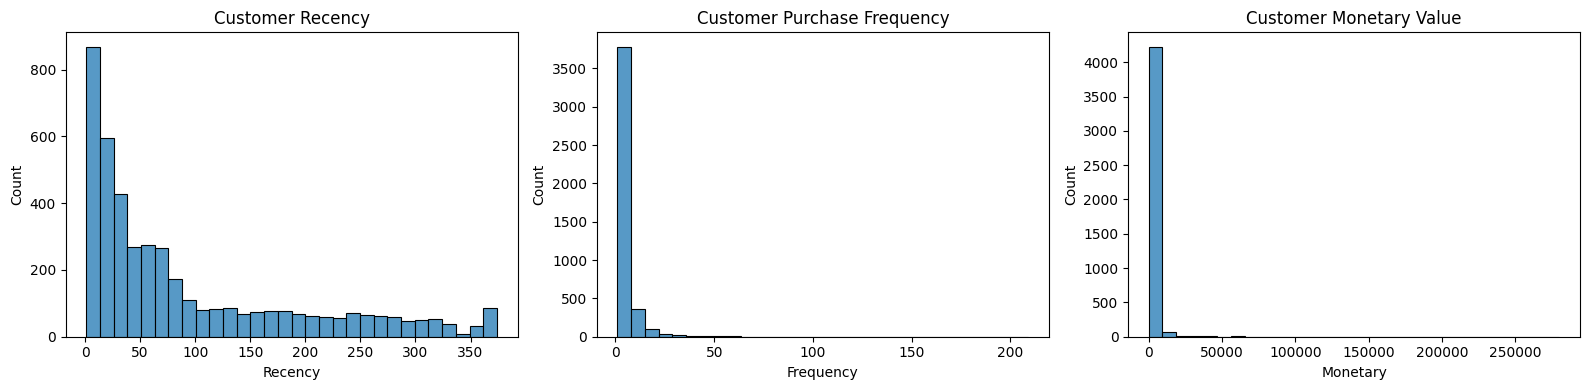

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=rfm, x="Recency", bins=30, ax=axes[0])
axes[0].set_title("Customer Recency")
sns.histplot(data=rfm, x="Frequency", bins=30, ax=axes[1])
axes[1].set_title("Customer Purchase Frequency")
sns.histplot(data=rfm, x="Monetary", bins=30, ax=axes[2])
axes[2].set_title("Customer Monetary Value")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

#Use log transformation to reduce skewness
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_features["Recency"] = np.log1p(rfm_features["Recency"])
rfm_features["Frequency"] = np.log1p(rfm_features["Frequency"])
rfm_features["Monetary"] = np.log1p(
    rfm_features["Monetary"].clip(lower=0)
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_features)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers assigned to each cluster:")
display(rfm["Cluster"].value_counts().sort_index())

Customers assigned to each cluster:


,count
Cluster,
0,713
1,1622
2,837
3,1166


In [28]:
cluster_summary = (
    rfm.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        TotalRevenue=("Monetary", "sum")
    ).round(2))
display(cluster_summary)

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,TotalRevenue
Cluster,,,,,
0,713,12.17,13.75,8088.02,5766757.07
1,1622,181.51,1.32,341.00,553099.77
2,837,17.70,2.19,557.32,466479.03
3,1166,71.64,4.08,1801.78,2100873.02


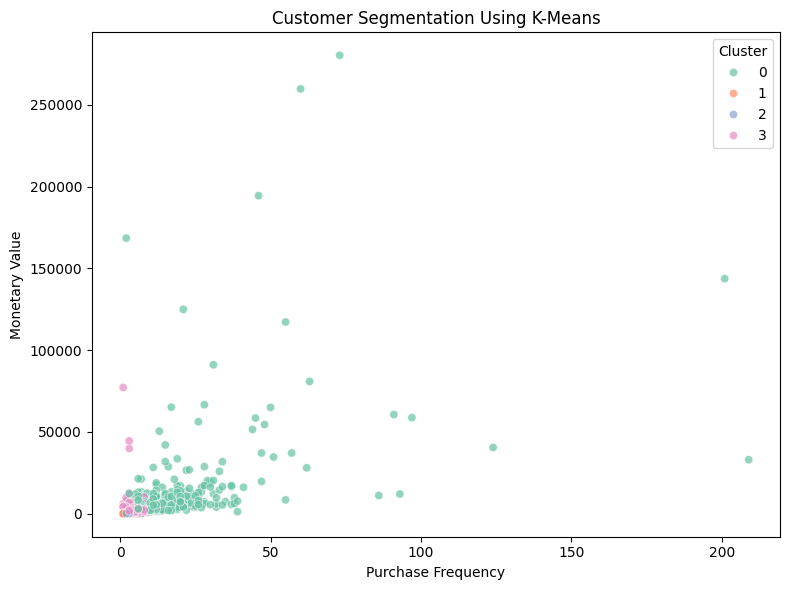

In [29]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value")
plt.tight_layout()
plt.show()

In [30]:
rfm.to_excel("Module_3_Customer_Segments.xlsx", index=False)
cluster_summary.to_excel("Module_3_Cluster_Summary.xlsx")

from google.colab import files
files.download("Module_3_Customer_Segments.xlsx")
files.download("Module_3_Cluster_Summary.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import pandas as pd
import numpy as np

print("Sales dataset shape:", sales_df.shape)
print("Date range:")
print(sales_df["InvoiceDate"].min())
print(sales_df["InvoiceDate"].max())

# Retain records with identifiable customers
ml_data = sales_df.dropna(subset=["CustomerID"]).copy()

ml_data["InvoiceDate"] = pd.to_datetime(ml_data["InvoiceDate"])
ml_data["LineTotal"] = ml_data["Quantity"] * ml_data["UnitPrice"]

print("Records available for ML:", len(ml_data))
print("Unique customers:", ml_data["CustomerID"].nunique())

display(ml_data.head())

Sales dataset shape: (524878, 11)
Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00
Records available for ML: 392692
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineTotal,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12


In [32]:
import pandas as pd
import numpy as np

# Prepare transaction data
ml_data = sales_df.dropna(subset=["CustomerID"]).copy()
ml_data["InvoiceDate"] = pd.to_datetime(ml_data["InvoiceDate"])
ml_data["LineTotal"] = ml_data["Quantity"] * ml_data["UnitPrice"]

# Normalize customer identifiers
ml_data["CustomerID"] = ml_data["CustomerID"].astype(str)

# Aggregate to one row per customer invoice
invoices = (
    ml_data.groupby(["CustomerID", "InvoiceNo"], as_index=False)
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        InvoiceValue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique")
    )
)

# Monthly prediction cutoffs; each needs a full 30-day outcome window
cutoffs = pd.date_range("2011-04-01", "2011-10-01", freq="MS")
snapshots = []

for cutoff in cutoffs:
    # Information available strictly before the prediction cutoff
    history = invoices[invoices["InvoiceDate"] < cutoff]

    # Purchases during the next 30 days determine the target
    future = invoices[
        (invoices["InvoiceDate"] >= cutoff) &
        (invoices["InvoiceDate"] < cutoff + pd.Timedelta(days=30))
    ]

    # Only customers with previous purchase history are eligible
    for customer_id, hist in history.groupby("CustomerID"):
        future_purchases = future[
            future["CustomerID"] == customer_id
        ]

        snapshots.append({
            "CustomerID": customer_id,
            "SnapshotDate": cutoff,
            "Recency": (cutoff - hist["InvoiceDate"].max()).days,
            "Frequency": hist["InvoiceNo"].nunique(),
            "Monetary": hist["InvoiceValue"].sum(),
            "AvgInvoiceValue": hist.groupby("InvoiceNo")["InvoiceValue"].sum().mean(),
            "TotalQuantity": hist["TotalQuantity"].sum(),
            "UniqueProducts": hist["UniqueProducts"].sum(),
            "RepeatPurchase30Days": int(len(future_purchases) > 0)
        })

model_data = pd.DataFrame(snapshots)

print("Prediction dataset shape:", model_data.shape)
print("\nTarget distribution:")
print(model_data["RepeatPurchase30Days"].value_counts())

display(model_data.head())

Prediction dataset shape: (20327, 9)

Target distribution:
RepeatPurchase30Days
0    14834
1     5493
Name: count, dtype: int64


,CustomerID,SnapshotDate,Recency,Frequency,Monetary,AvgInvoiceValue,TotalQuantity,UniqueProducts,RepeatPurchase30Days
0,12346.0,2011-04-01,72,1,77183.60,77183.600,74215,1,0
1,12347.0,2011-04-01,64,2,1187.18,593.590,634,60,1
2,12348.0,2011-04-01,65,2,1120.24,560.120,1855,19,1
3,12350.0,2011-04-01,57,1,334.40,334.400,197,17,0
4,12352.0,2011-04-01,9,5,1561.81,312.362,254,36,0


In [33]:
print("Snapshot dates:")
print(sorted(model_data["SnapshotDate"].unique()))

print("\nTarget distribution by snapshot:")
display(
    model_data.groupby("SnapshotDate")["RepeatPurchase30Days"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

print("\nMissing feature values:")
print(model_data.isnull().sum())

Snapshot dates:
[Timestamp('2011-04-01 00:00:00'), Timestamp('2011-05-01 00:00:00'), Timestamp('2011-06-01 00:00:00'), Timestamp('2011-07-01 00:00:00'), Timestamp('2011-08-01 00:00:00'), Timestamp('2011-09-01 00:00:00'), Timestamp('2011-10-01 00:00:00')]

Target distribution by snapshot:


,count,sum,mean
SnapshotDate,,,
2011-04-01,2134,556,0.261
2011-05-01,2434,752,0.309
2011-06-01,2718,749,0.276
2011-07-01,2960,743,0.251
2011-08-01,3148,749,0.238
2011-09-01,3317,967,0.292
2011-10-01,3616,977,0.270



Missing feature values:
CustomerID              0
SnapshotDate            0
Recency                 0
Frequency               0
Monetary                0
AvgInvoiceValue         0
TotalQuantity           0
UniqueProducts          0
RepeatPurchase30Days    0
dtype: int64


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Define input features and target
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgInvoiceValue",
    "TotalQuantity",
    "UniqueProducts"
]

target = "RepeatPurchase30Days"

# Chronological split
train_data = model_data[
    model_data["SnapshotDate"] < "2011-10-01"
].copy()

test_data = model_data[
    model_data["SnapshotDate"] == "2011-10-01"
].copy()

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:",
      train_data["SnapshotDate"].min(),
      "to",
      train_data["SnapshotDate"].max())

print("Testing period:",
      test_data["SnapshotDate"].min(),
      "to",
      test_data["SnapshotDate"].max())

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 16711
Testing records: 3616

Training period: 2011-04-01 00:00:00 to 2011-09-01 00:00:00
Testing period: 2011-10-01 00:00:00 to 2011-10-01 00:00:00

Training target distribution:
RepeatPurchase30Days
0    0.73
1    0.27
Name: proportion, dtype: float64

Testing target distribution:
RepeatPurchase30Days
0    0.73
1    0.27
Name: proportion, dtype: float64


In [35]:
#Create Logistic Regression pipeline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")
print(classification_report(y_test, lr_predictions))

Logistic Regression Results
              precision    recall  f1-score   support

           0       0.79      0.92      0.85      2639
           1       0.60      0.33      0.43       977

    accuracy                           0.76      3616
   macro avg       0.70      0.63      0.64      3616
weighted avg       0.74      0.76      0.74      3616



In [36]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print(classification_report(y_test, rf_predictions))

Random Forest Results
              precision    recall  f1-score   support

           0       0.83      0.74      0.78      2639
           1       0.45      0.58      0.51       977

    accuracy                           0.70      3616
   macro avg       0.64      0.66      0.64      3616
weighted avg       0.72      0.70      0.71      3616



In [37]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7611,0.6048,0.3337,0.4301,0.7230
1,Random Forest,0.6952,0.4503,0.5793,0.5067,0.7226


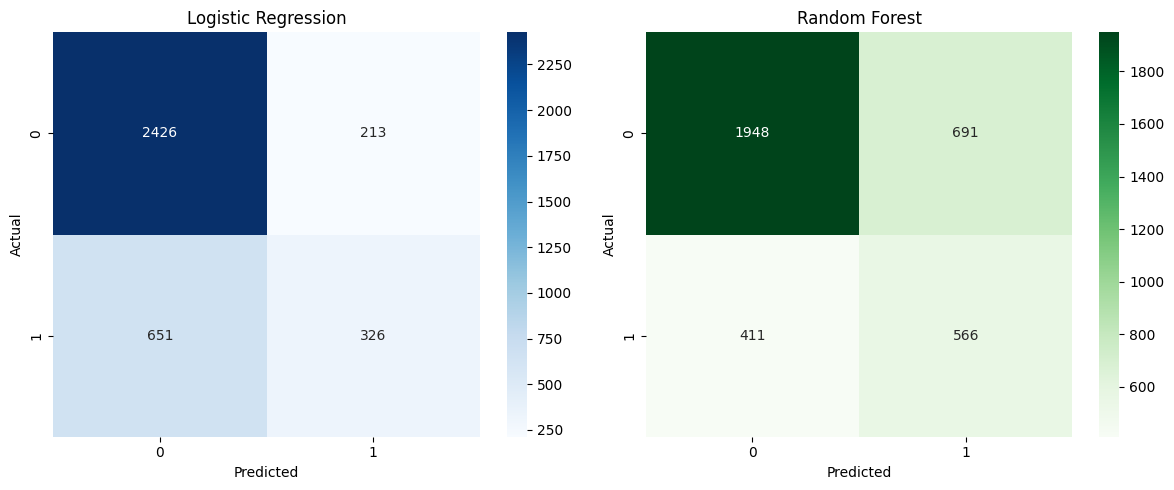

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression confusion matrix
sns.heatmap(
    confusion_matrix(y_test, lr_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest confusion matrix
sns.heatmap(
    confusion_matrix(y_test, rf_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [40]:
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7611,0.6048,0.3337,0.4301,0.7230
1,Random Forest,0.6952,0.4503,0.5793,0.5067,0.7226


In [41]:
import joblib

joblib.dump(lr_model, "Logistic_Regression_Model.pkl")
joblib.dump(rf_model, "Random_Forest_Model.pkl")

results.to_excel("Module_4_Model_Comparison.xlsx", index=False)

from google.colab import files

files.download("Logistic_Regression_Model.pkl")
files.download("Random_Forest_Model.pkl")
files.download("Module_4_Model_Comparison.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>